## End to end Deep Learning Project Using Simple RNN

In [17]:
# Import libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, Dense
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [18]:
# Set parameters
max_features = 10000
max_len = 500

In [19]:
# Load the IMDB dataset
(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=max_features
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (25000,)
X_test: (25000,)


In [20]:
# Pad sequences
X_train = pad_sequences(
    X_train,
    maxlen=max_len,
    padding='pre',
    truncating='pre'
)

X_test = pad_sequences(
    X_test,
    maxlen=max_len,
    padding='pre',
    truncating='pre'
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (25000, 500)
X_test: (25000, 500)


In [21]:
# Build the model
model = Sequential([
    Input(shape=(max_len,)),
    Embedding(
        input_dim=max_features,
        output_dim=128,
        mask_zero=True
    ),
    SimpleRNN(
        128,
        activation='tanh'
    ),
    Dense(1, activation='sigmoid')
])

In [22]:
# Model summary
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 500, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,313,025 (5.01 MB)

 Trainable params: 1,313,025 (5.01 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:
# Compile the model
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [24]:
# Configure EarlyStopping
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

In [25]:
# Train the model
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping]
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 31s 45ms/step - accuracy: 0.5617 - loss: 0.6801 - val_accuracy: 0.5776 - val_loss: 0.6812
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 43ms/step - accuracy: 0.6830 - loss: 0.6113 - val_accuracy: 0.8124 - val_loss: 0.4325
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 42ms/step - accuracy: 0.8672 - loss: 0.3360 - val_accuracy: 0.8450 - val_loss: 0.3821
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 43ms/step - accuracy: 0.9247 - loss: 0.2072 - val_accuracy: 0.8610 - val_loss: 0.3506
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 43ms/step - accuracy: 0.9593 - loss: 0.1280 - val_accuracy: 0.8644 - val_loss: 0.3470
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 43ms/step - accuracy: 0.9800 - loss: 0.0736 - val_accuracy: 0.8604 - val_loss: 0.3695
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 43ms/step - accuracy: 0.9894 - loss: 0.0412 - val_accuracy: 0.8318 - val_loss: 0.4236


In [26]:
# Evaluate the model
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.8534 - loss: 0.3615
Test Loss: 0.3615334630012512
Test Accuracy: 0.85343998670578


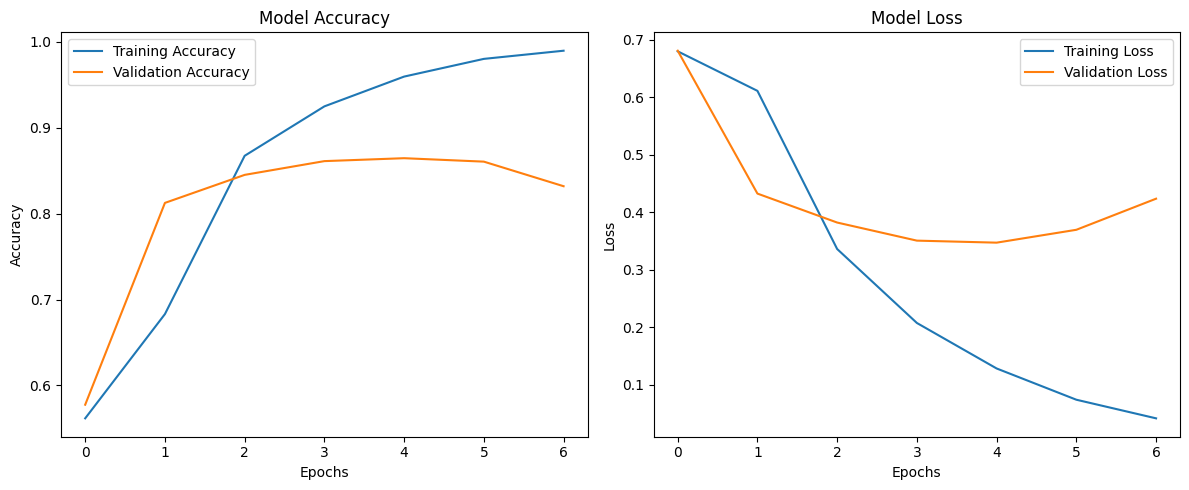

In [27]:
# Plot accuracy and loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [28]:
# Save the model
model.save("simple_rnn_imdb.keras")

print("Model saved successfully!")

Model saved successfully!


In [29]:
import os

print("Current directory:", os.getcwd())
print("Files:", os.listdir())

Current directory: /content
Files: ['.config', 'simple_rnn_imdb.h5', 'simple_rnn_imdb.keras', 'requirements.txt', 'sample_data']


In [31]:
from google.colab import files

files.download('/content/simple_rnn_imdb.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>